# Анотація
Генерація зашумлених датасетів на основі обраних еталонних RGB-знімків Sentinel-2. Для забезпечення відтворюваності подальших експериментів (Ablation Study) тут створюються та зберігаються набори даних із трьома цільовими моделями спотворень:

Адитивний гаусовий шум: генерується з різними рівнями дисперсії для імітації теплових та сенсорних завад апаратури.

Імпульсний шум ("сіль та перець"): накладається для моделювання наявності битих пікселів матриці або втрат при передачі телеметрії.

Сигнально-залежний шум: формується для підготовки даних до подальших експериментів із застосуванням варіаційно-стабілізуючих перетворень (ВСП).

### Обґрунтування вибору моделі сигнально-залежного шуму та застосування ВСП

Оскільки в даному дослідженні використовуються мультиспектральні оптичні дані супутника Sentinel-2 (канали видимого спектра), для моделювання сигнально-залежних спотворень обрано пуассонівський (фотонний) шум.

**1. Фізична природа пуассонівського шуму в оптичних сенсорах**
Оптичні сенсори (такі як матриці, що встановлені на Sentinel-2) формують зображення шляхом підрахунку кількості фотонів, які потрапляють на детектор за час експозиції. Процес випромінювання та реєстрації фотонів має квантову природу і є випадковим. Ця дискретна випадковість описується розподілом Пуассона. На відміну від радарних знімків, де домінує мультиплікативний спекл через інтерференцію когерентних хвиль, головним джерелом сигнально-залежних завад в оптичному дистанційному зондуванні є саме "дробовий шум" (photon shot noise), викликаний флуктуаціями потоку фотонів. Згідно з фундаментальними дослідженнями моделювання шуму в оптичних сенсорах, саме пуассонівська складова є домінуючою для сигналозалежних спотворень [1].

**2. Проблема сигнально-залежної дисперсії**
Головна складність роботи з пуассонівським шумом полягає в тому, що його дисперсія (сила розкиду значень) дорівнює його математичному сподіванню. Простою мовою: чим яскравіший піксель (наприклад, світла міська забудова або відкритий ґрунт), тим інтенсивнішим на ньому є абсолютне значення шуму.
Більшість класичних алгоритмів обробки зображень (включно зі згладжувальними фільтрами або текстурними дескрипторами) математично розроблені з припущенням, що шум є адитивним білим гаусовим (AWGN) — тобто його сила однакова на всьому зображенні, незалежно від яскравості пікселів. Застосування таких алгоритмів напряму до пуассонівського шуму призводить до нестабільних результатів: темні ділянки можуть бути перезгладжені, а світлі — залишитися зашумленими.

**3. Механізм перетворення Анскомба (варіаційно-стабілізуюче перетворення - ВСП)**
Для вирішення цього конфлікту у конвеєр обробки буде інтегровано перетворення Анскомба. Це класичне варіаційно-стабілізуюче перетворення (ВСП), яке використовує нелінійну функцію квадратного кореня (функція `anscombe_transform`: $2 \cdot \sqrt{x + \frac{3}{8}}$).
Її завдання — "відв'язати" дисперсію шуму від інтенсивності корисного сигналу. Після прямого перетворення Анскомба пуассонівські дані набувають властивостей, наближених до гаусового розподілу зі стабільною дисперсією $\approx 1$ на всьому зображенні [2].

Це створює ідеальні умови для наступного кроку:

1. **Фільтрація у просторі ВСП:** Оскільки дисперсія тепер стабільна, стандартні алгоритми (наприклад, `cv2.GaussianBlur` або більш складні просторові фільтри) працюють коректно і рівномірно на всіх ділянках кадру.
2. **Зворотне перетворення:** Після придушення гаусоподібного шуму дані повертаються у вихідний простір яскравостей за допомогою зворотного алгебраїчного перетворення (`inverse_anscombe_transform`), відновлюючи коректний динамічний діапазон зображення [2].

---

**Використані джерела:**

[1] A. Foi, M. Trimeche, V. Katkovnik and K. Egiazarian, "Practical Poissonian-Gaussian Noise Modeling and Fitting for Single-Image Raw-Data," in *IEEE Transactions on Image Processing*, vol. 17, no. 10, pp. 1737-1754, Oct. 2008. **DOI: 10.1109/TIP.2008.2001399**

[2] M. Makitalo and A. Foi, "Optimal Inversion of the Anscombe Transformation in Low-Count Poisson Image Denoising," in *IEEE Transactions on Image Processing*, vol. 20, no. 1, pp. 99-109, Jan. 2011. **DOI: 10.1109/TIP.2010.2056693**

In [5]:
#%pip install opencv-python numpy matplotlib scikit-image

In [27]:
# Importing the Necessary Libraries
# The main ones here are XGBoost and local_binary_pattern.

import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

In [28]:
def calculate_psnr(original, noisy):
    """
    Calculates PSNR (Peak Signal-to-Noise Ratio) using OpenCV's built-in method.

    :param original: Original image as a NumPy array.
    :param noisy: Noisy image as a NumPy array.
    :return: PSNR value in decibels (float). Returns `inf` if the images are identical.
    """
    # Verify that the dimensions of the images match
    if original.shape != noisy.shape:
        raise ValueError("Original and noisy images must have the same shape.")

    # Use OpenCV's PSNR function
    psnr = cv2.PSNR(original, noisy)
    return psnr

In [29]:
#Generate images with AWGN noise

def add_gaussian_noise(image, variance):
    """
    Додає адитивний гаусовий шум до зображення.
    variance (сигма у квадраті) визначає інтенсивність шуму.
    """
    row, col, ch = image.shape
    sigma = variance ** 0.5
    # Генерація шуму з нормальним розподілом N(0, sigma)
    noise = np.random.normal(0, sigma, (row, col, ch))
    
    # Додавання шуму та відсікання значень, що вийшли за межі [0, 255]
    noisy_image = image.astype(np.float32) + noise
    noisy_image = np.clip(noisy_image, 0, 255).astype(np.uint8)
    
    return noisy_image

In [30]:
# Generate image with Solt&paper

def add_salt_and_pepper_noise(image, percentage):
    """
    Додає імпульсний шум (сіль та перець) до зображення.
    percentage (1, 5, 20) визначає точний відсоток пошкоджених пікселів.
    """
    row, col, ch = image.shape
    noisy_image = np.copy(image)
    
    amount = percentage / 100.0
    num_pixels = row * col
    num_noisy = int(amount * num_pixels)
    
    # Випадковий вибір унікальних індексів пікселів (БЕЗ ПОВТОРЕНЬ)
    noisy_indices = np.random.choice(num_pixels, num_noisy, replace=False)
    
    # Ділимо індекси навпіл для солі та перцю
    salt_indices = noisy_indices[:num_noisy // 2]
    pepper_indices = noisy_indices[num_noisy // 2:]
    
    # Перетворюємо 1D індекси у 2D координати
    salt_coords = np.unravel_index(salt_indices, (row, col))
    pepper_coords = np.unravel_index(pepper_indices, (row, col))
    
    # Застосовуємо шум одразу до всіх каналів
    noisy_image[salt_coords[0], salt_coords[1], :] = 255
    noisy_image[pepper_coords[0], pepper_coords[1], :] = 0
    
    return noisy_image

In [31]:
# Генерація Пуасонівського шуму
def add_poisson_noise(image, peak):
    """
    Додає пуассонівський (фотонний) сигнально-залежний шум.
    peak: імітує максимальну кількість фотонів. Менше значення = сильніший шум.
    """
    # Нормалізація зображення у діапазон [0, 1]
    image_normalized = image.astype(np.float32) / 255.0
    
    # Генерація пуассонівського розподілу на основі масштабованої інтенсивності
    noisy_image = np.random.poisson(image_normalized * peak) / float(peak)
    
    # Повернення у 8-бітний формат із відсіканням аномалій
    noisy_image = np.clip(noisy_image * 255, 0, 255).astype(np.uint8)
    
    return noisy_image

In [33]:
# ВСП
def anscombe_transform(image):
    """Пряме ВСП (перетворення Анскомба)."""
    # Формула: 2 * sqrt(x + 3/8)
    # Зображення переводиться у float для уникнення переповнення
    return 2.0 * np.sqrt(image.astype(np.float32) + (3.0 / 8.0))

def inverse_anscombe_transform(vst_image):
    """Зворотне ВСП (алгебраїчне)."""
    # Формула: (y / 2)^2 - 3/8
    inverse = (vst_image / 2.0)**2 - (3.0 / 8.0)
    return np.clip(inverse, 0, 255).astype(np.uint8)


[*] Обробка зображення: SS1
  [!] Увага: 'data/SS1_awgn_var_25.bmp' вже існує. Зчитуємо зображення з диска.
  [+] PSNR (var=25): 34.42 dB
  [!] Увага: 'data/SS1_awgn_var_50.bmp' вже існує. Зчитуємо зображення з диска.
  [+] PSNR (var=50): 31.57 dB
  [!] Увага: 'data/SS1_awgn_var_100.bmp' вже існує. Зчитуємо зображення з диска.
  [+] PSNR (var=100): 28.73 dB

[*] Обробка зображення: SS2
  [!] Увага: 'data/SS2_awgn_var_25.bmp' вже існує. Зчитуємо зображення з диска.
  [+] PSNR (var=25): 34.17 dB
  [!] Увага: 'data/SS2_awgn_var_50.bmp' вже існує. Зчитуємо зображення з диска.
  [+] PSNR (var=50): 31.20 dB
  [!] Увага: 'data/SS2_awgn_var_100.bmp' вже існує. Зчитуємо зображення з диска.
  [+] PSNR (var=100): 28.26 dB


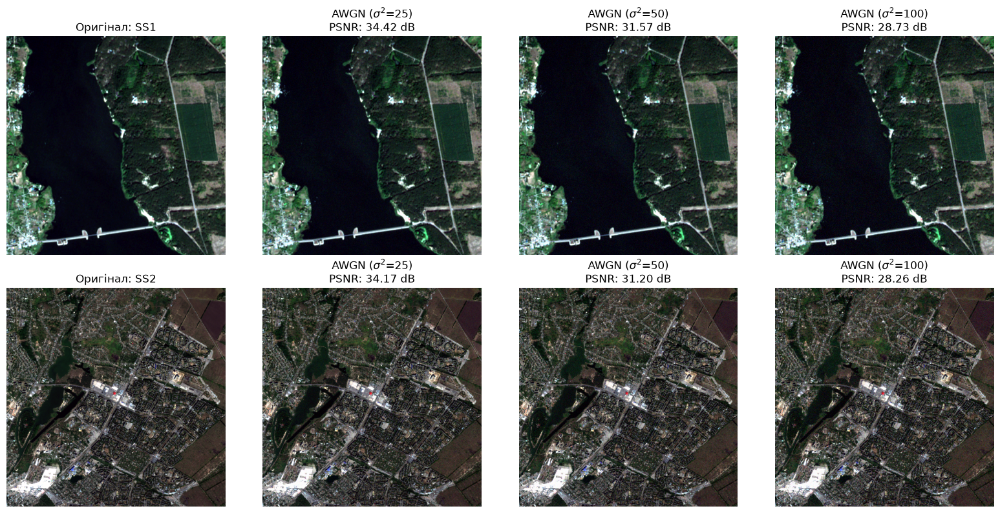


[+] Генерацію завершено. 0 нових зображень збережено у директорію 'data/'.


In [34]:
# MAIN 1. Generate images with AWGN
def main():
    output_dir = "data"
    os.makedirs(output_dir, exist_ok=True)
    
    # Масив вхідних зображень
    input_images = ["data/SS1.bmp", "data/SS2.bmp"]
    gaussian_variances = [25, 50, 100]
    
    # Створення сітки графіків: рядки = кількість зображень, стовпці = оригінал + 3 варіанти шуму
    fig, axes = plt.subplots(len(input_images), len(gaussian_variances) + 1, figsize=(16, 4 * len(input_images)))
    
    # Запобіжник на випадок, якщо в масиві лише 1 зображення
    if len(input_images) == 1:
        axes = [axes]
        
    total_saved = 0
    
    for i, img_path in enumerate(input_images):
        image_bgr = cv2.imread(img_path)
        
        if image_bgr is None:
            print(f"[!] Помилка: Файл {img_path} не знайдено.")
            continue
            
        # Отримання імені файлу без розширення (наприклад, "SS1")
        base_name = os.path.splitext(os.path.basename(img_path))[0]
        print(f"\n[*] Обробка зображення: {base_name}")
        
        image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
        axes[i, 0].imshow(image_rgb)
        axes[i, 0].set_title(f"Оригінал: {base_name}")
        axes[i, 0].axis('off')
        
        for j, var in enumerate(gaussian_variances):
            out_filename = os.path.join(output_dir, f"{base_name}_awgn_var_{var}.bmp")
            
            # --- Перевірка існування файлу ---
            if os.path.exists(out_filename):
                print(f"  [!] Увага: '{out_filename}' вже існує. Зчитуємо зображення з диска.")
                noisy_bgr = cv2.imread(out_filename)
            else:
                noisy_bgr = add_gaussian_noise(image_bgr, var)
                cv2.imwrite(out_filename, noisy_bgr)
                total_saved += 1
            
            # --- Розрахунок PSNR ---
            psnr_val = calculate_psnr(image_bgr, noisy_bgr)
            print(f"  [+] PSNR (var={var}): {psnr_val:.2f} dB")
            
            noisy_rgb = cv2.cvtColor(noisy_bgr, cv2.COLOR_BGR2RGB)
            axes[i, j+1].imshow(noisy_rgb)
            axes[i, j+1].set_title(rf"AWGN ($\sigma^2$={var})" + "\n" + f"PSNR: {psnr_val:.2f} dB")
            axes[i, j+1].axis('off')
            
    plt.tight_layout()
    plt.show()
    
    print(f"\n[+] Генерацію завершено. {total_saved} нових зображень збережено у директорію '{output_dir}/'.")

if __name__ == "__main__":
    main()


[*] Обробка зображення: SS1
  [!] Увага: 'data/SS1_sp_1pct.bmp' вже існує. Зчитуємо зображення з диска.
  [+] PSNR для S&P (1%): 24.05 dB
  [!] Увага: 'data/SS1_sp_5pct.bmp' вже існує. Зчитуємо зображення з диска.
  [+] PSNR для S&P (5%): 17.04 dB
  [!] Увага: 'data/SS1_sp_20pct.bmp' вже існує. Зчитуємо зображення з диска.
  [+] PSNR для S&P (20%): 11.01 dB

[*] Обробка зображення: SS2
  [!] Увага: 'data/SS2_sp_1pct.bmp' вже існує. Зчитуємо зображення з диска.
  [+] PSNR для S&P (1%): 24.65 dB
  [!] Увага: 'data/SS2_sp_5pct.bmp' вже існує. Зчитуємо зображення з диска.
  [+] PSNR для S&P (5%): 17.64 dB
  [!] Увага: 'data/SS2_sp_20pct.bmp' вже існує. Зчитуємо зображення з диска.
  [+] PSNR для S&P (20%): 11.59 dB


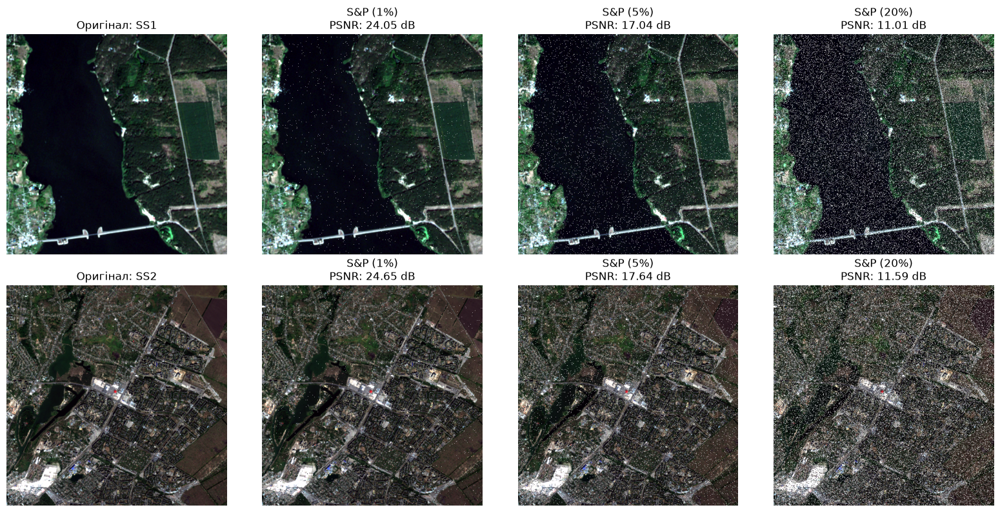


[+] Роботу завершено. Створено нових зображень: 0.


In [35]:
# MAIN 2. Генерація зображень з шумом сіль та перець
def main():
    output_dir = "data"
    os.makedirs(output_dir, exist_ok=True)
    
    input_images = ["data/SS1.bmp", "data/SS2.bmp"]
    sp_percentages = [1, 5, 20]
    
    fig, axes = plt.subplots(len(input_images), len(sp_percentages) + 1, figsize=(16, 4 * len(input_images)))
    
    if len(input_images) == 1:
        axes = [axes]
        
    total_saved = 0
    
    for i, img_path in enumerate(input_images):
        image_bgr = cv2.imread(img_path)
        
        if image_bgr is None:
            print(f"[!] Помилка: Файл {img_path} не знайдено.")
            continue
            
        base_name = os.path.splitext(os.path.basename(img_path))[0]
        print(f"\n[*] Обробка зображення: {base_name}")
        
        image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
        axes[i, 0].imshow(image_rgb)
        axes[i, 0].set_title(f"Оригінал: {base_name}")
        axes[i, 0].axis('off')
        
        for j, sp in enumerate(sp_percentages):
            out_filename = os.path.join(output_dir, f"{base_name}_sp_{sp}pct.bmp")
            
            # --- ПЕРЕВІРКА ІСНУВАННЯ ЗОБРАЖЕННЯ ---
            if os.path.exists(out_filename):
                print(f"  [!] Увага: '{out_filename}' вже існує. Зчитуємо зображення з диска.")
                noisy_bgr = cv2.imread(out_filename)
            else:
                # Генеруємо нове, якщо файлу немає
                noisy_bgr = add_salt_and_pepper_noise(image_bgr, sp)
                cv2.imwrite(out_filename, noisy_bgr)
                total_saved += 1
            
            # --- РОЗРАХУНОК PSNR ---
            psnr_val = calculate_psnr(image_bgr, noisy_bgr)
            print(f"  [+] PSNR для S&P ({sp}%): {psnr_val:.2f} dB")
            
            noisy_rgb = cv2.cvtColor(noisy_bgr, cv2.COLOR_BGR2RGB)
            axes[i, j+1].imshow(noisy_rgb)
            axes[i, j+1].set_title(f"S&P ({sp}%)\nPSNR: {psnr_val:.2f} dB")
            axes[i, j+1].axis('off')
            
    plt.tight_layout()
    plt.show()
    
    print(f"\n[+] Роботу завершено. Створено нових зображень: {total_saved}.")

if __name__ == "__main__":
    main()


[*] Обробка зображення: SS1
  [!] Увага: 'data/SS1_poisson_peak_100.bmp' вже існує. Зчитуємо зображення з диска.
  [+] PSNR для Poisson (peak=100): 27.93 dB
  [+] PSNR для Poisson (peak=80): 26.96 dB
  [+] PSNR для Poisson (peak=60): 25.72 dB
  [+] PSNR для Poisson (peak=40): 24.00 dB
  [!] Увага: 'data/SS1_poisson_peak_30.bmp' вже існує. Зчитуємо зображення з диска.
  [+] PSNR для Poisson (peak=30): 22.76 dB
  [+] PSNR для Poisson (peak=20): 21.06 dB
  [!] Увага: 'data/SS1_poisson_peak_10.bmp' вже існує. Зчитуємо зображення з диска.
  [+] PSNR для Poisson (peak=10): 18.15 dB
  [+] PSNR для Poisson (peak=5): 15.40 dB

[*] Обробка зображення: SS2
  [!] Увага: 'data/SS2_poisson_peak_100.bmp' вже існує. Зчитуємо зображення з диска.
  [+] PSNR для Poisson (peak=100): 26.25 dB
  [+] PSNR для Poisson (peak=80): 25.30 dB
  [+] PSNR для Poisson (peak=60): 24.06 dB
  [+] PSNR для Poisson (peak=40): 22.31 dB
  [!] Увага: 'data/SS2_poisson_peak_30.bmp' вже існує. Зчитуємо зображення з диска.
  [

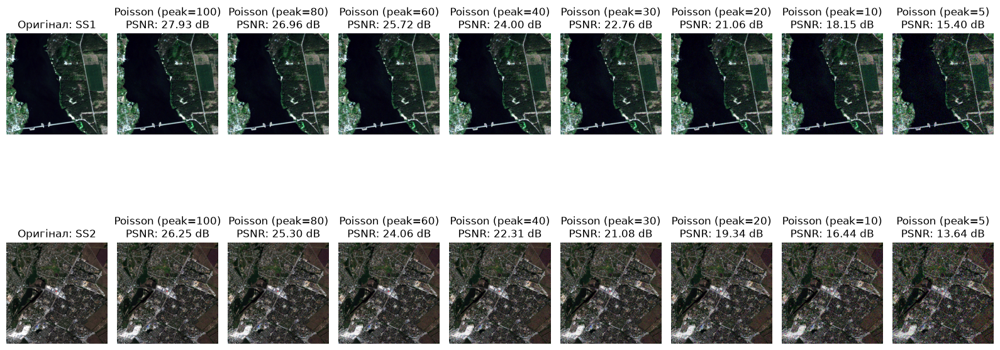


[+] Роботу завершено. Створено нових зображень: 10.


In [38]:
# MAIN 3. Генерація зображень з Пуассонівським шумом (який імітує сигнально заежний шум)
def main():
    output_dir = "data"
    os.makedirs(output_dir, exist_ok=True)
    
    input_images = ["data/SS1.bmp", "data/SS2.bmp"]
    # Параметри peak: 100 (слабкий шум), 30 (середній), 10 (сильний)
    noise_peaks = [100, 80, 60, 40, 30, 20, 10, 5] 
    
    fig, axes = plt.subplots(len(input_images), len(noise_peaks) + 1, figsize=(16, 4 * len(input_images)))
    
    if len(input_images) == 1:
        axes = [axes]
        
    total_saved = 0
    
    for i, img_path in enumerate(input_images):
        image_bgr = cv2.imread(img_path)
        
        if image_bgr is None:
            print(f"[!] Помилка: Файл {img_path} не знайдено.")
            continue
            
        base_name = os.path.splitext(os.path.basename(img_path))[0]
        print(f"\n[*] Обробка зображення: {base_name}")
        
        image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
        axes[i, 0].imshow(image_rgb)
        axes[i, 0].set_title(f"Оригінал: {base_name}")
        axes[i, 0].axis('off')
        
        for j, peak in enumerate(noise_peaks):
            out_filename = os.path.join(output_dir, f"{base_name}_poisson_peak_{peak}.bmp")
            
            # --- ПЕРЕВІРКА ІСНУВАННЯ ЗОБРАЖЕННЯ ---
            if os.path.exists(out_filename):
                print(f"  [!] Увага: '{out_filename}' вже існує. Зчитуємо зображення з диска.")
                noisy_bgr = cv2.imread(out_filename)
            else:
                # Генеруємо нове, якщо файлу немає
                noisy_bgr = add_poisson_noise(image_bgr, peak)
                cv2.imwrite(out_filename, noisy_bgr)
                total_saved += 1
            
            # --- РОЗРАХУНОК PSNR ---
            psnr_val = calculate_psnr(image_bgr, noisy_bgr)
            print(f"  [+] PSNR для Poisson (peak={peak}): {psnr_val:.2f} dB")
            
            noisy_rgb = cv2.cvtColor(noisy_bgr, cv2.COLOR_BGR2RGB)
            axes[i, j+1].imshow(noisy_rgb)
            axes[i, j+1].set_title(rf"Poisson (peak={peak})" + "\n" + f"PSNR: {psnr_val:.2f} dB")
            axes[i, j+1].axis('off')
            
    plt.tight_layout()
    plt.show()
    
    print(f"\n[+] Роботу завершено. Створено нових зображень: {total_saved}.")

if __name__ == "__main__":
    main()


[*] Аналіз зображення: SS1
  [-] Шум (peak=100): PSNR = 27.93 dB | Після ВСП: PSNR = 31.77 dB | Покращення: +3.84 dB
  [-] Шум (peak=30): PSNR = 22.76 dB | Після ВСП: PSNR = 28.86 dB | Покращення: +6.10 dB
  [-] Шум (peak=10): PSNR = 18.15 dB | Після ВСП: PSNR = 24.57 dB | Покращення: +6.41 dB

[*] Аналіз зображення: SS2
  [-] Шум (peak=100): PSNR = 26.25 dB | Після ВСП: PSNR = 24.52 dB | Покращення: -1.74 dB
  [-] Шум (peak=30): PSNR = 21.08 dB | Після ВСП: PSNR = 23.51 dB | Покращення: +2.43 dB
  [-] Шум (peak=10): PSNR = 16.44 dB | Після ВСП: PSNR = 21.01 dB | Покращення: +4.58 dB


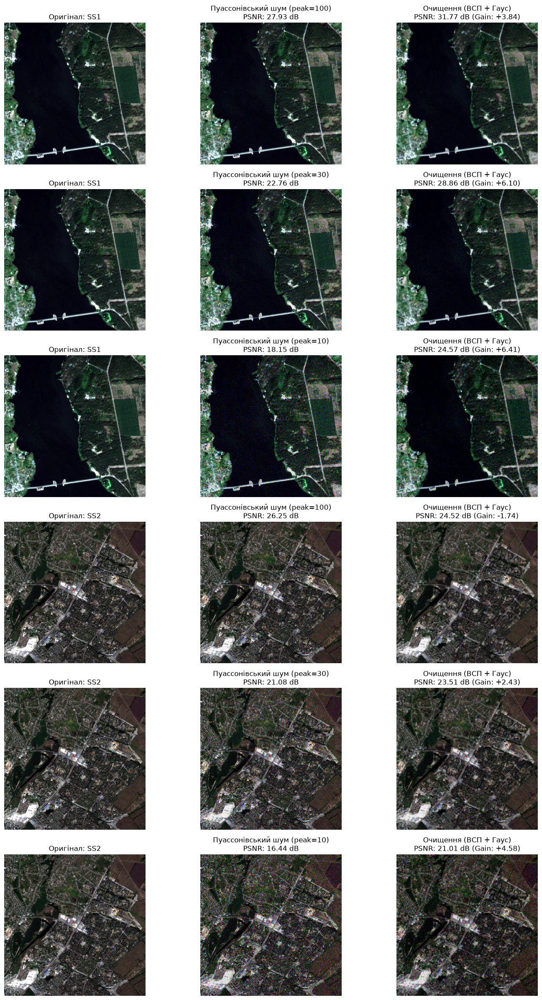

In [37]:
# MAIN 4. Застосування ВСП та оцінка результатів
def main():
    input_images = ["SS1", "SS2"]
    noise_peaks = [100, 30, 10] # Від слабкого до сильного
    
    total_files = len(input_images) * len(noise_peaks)
    fig, axes = plt.subplots(total_files, 3, figsize=(15, 4 * total_files))
    
    row_idx = 0
    
    for base_name in input_images:
        orig_path = os.path.join("data", f"{base_name}.bmp")
        original_image = cv2.imread(orig_path)
        
        if original_image is None:
            print(f"[!] Помилка: Оригінал {orig_path} не знайдено.")
            continue
            
        original_rgb = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)
        print(f"\n[*] Аналіз зображення: {base_name}")
        
        for peak in noise_peaks:
            noisy_path = os.path.join("data", f"{base_name}_poisson_peak_{peak}.bmp")
            noisy_image = cv2.imread(noisy_path)
            
            if noisy_image is None:
                print(f"  [!] Файл {noisy_path} не знайдено, пропускаємо.")
                continue
                
            # --- ЗАСТОСУВАННЯ ВСП ---
            vst_image = anscombe_transform(noisy_image)
            # Фільтрація Гауса у стабілізованому просторі
            vst_filtered = cv2.GaussianBlur(vst_image, (3, 3), 1.0)
            cleaned = inverse_anscombe_transform(vst_filtered)
            
            # --- РОЗРАХУНОК PSNR ---
            psnr_noisy = calculate_psnr(original_image, noisy_image)
            psnr_cleaned = calculate_psnr(original_image, cleaned)
            psnr_gain = psnr_cleaned - psnr_noisy
            
            print(f"  [-] Шум (peak={peak}): PSNR = {psnr_noisy:.2f} dB "
                  f"| Після ВСП: PSNR = {psnr_cleaned:.2f} dB "
                  f"| Покращення: {psnr_gain:+.2f} dB")
            
            noisy_rgb = cv2.cvtColor(noisy_image, cv2.COLOR_BGR2RGB)
            cleaned_rgb = cv2.cvtColor(cleaned, cv2.COLOR_BGR2RGB)
            
            # --- ВІЗУАЛІЗАЦІЯ ---
            axes[row_idx, 0].imshow(original_rgb)
            axes[row_idx, 0].set_title(f"Оригінал: {base_name}")
            axes[row_idx, 0].axis('off')
            
            axes[row_idx, 1].imshow(noisy_rgb)
            axes[row_idx, 1].set_title(rf"Пуассонівський шум (peak={peak})" + f"\nPSNR: {psnr_noisy:.2f} dB")
            axes[row_idx, 1].axis('off')
            
            axes[row_idx, 2].imshow(cleaned_rgb)
            axes[row_idx, 2].set_title(rf"Очищення (ВСП + Гаус)" + f"\nPSNR: {psnr_cleaned:.2f} dB (Gain: {psnr_gain:+.2f})")
            axes[row_idx, 2].axis('off')
            
            row_idx += 1
            
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    main()